# Student Exam Score Prediction using Simple Linear Regression

## Problem Statement
The goal is to understand whether study hours can help
predict a student's exam score using Simple Linear Regression.


## 1. Understanding the Data

### 1.1 Import Libraries and Load Dataset

In this section, we load the dataset into a Pandas DataFrame and inspect its structure before building a machine learning model.

**Why is this step important?**

Understanding the dataset helps us identify the available columns, the number of records, data types, missing values, and the variables relevant to our prediction problem.

In [1]:
import pandas as pd
df = pd.read_csv("../data/student_exam_scores.csv")
df.head()

,student_id,hours_studied,sleep_hours,attendance_percent,previous_scores,exam_score
0,S001,8.0,8.8,72.1,45,30.2
1,S002,1.3,8.6,60.7,55,25.0
2,S003,4.0,8.2,73.7,86,35.8
3,S004,3.5,4.8,95.1,66,34.0
4,S005,9.1,6.4,89.8,71,40.3


### 1.2 Dataset Dimensions

The `shape` attribute returns the number of rows and columns in the dataset.

- **Rows:** Represent individual records.
- **Columns:** Represent variables or attributes.

This helps us understand the size of the dataset before performing further analysis.

In [2]:
print("Shape:")
print(df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nDescriptive Statistics:")
display(df.describe().T)

Shape:
(200, 6)

Columns:
['student_id', 'hours_studied', 'sleep_hours', 'attendance_percent', 'previous_scores', 'exam_score']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   student_id          200 non-null    object 
 1   hours_studied       200 non-null    float64
 2   sleep_hours         200 non-null    float64
 3   attendance_percent  200 non-null    float64
 4   previous_scores     200 non-null    int64  
 5   exam_score          200 non-null    float64
dtypes: float64(4), int64(1), object(1)
memory usage: 9.5+ KB

Descriptive Statistics:


,count,mean,std,min,25%,50%,75%,max
hours_studied,200.0,6.3255,3.227317,1.0,3.5,6.15,9.000,12.0
sleep_hours,200.0,6.6220,1.497138,4.0,5.3,6.70,8.025,9.0
attendance_percent,200.0,74.8300,14.249905,50.3,62.2,75.25,87.425,100.0
previous_scores,200.0,66.8000,15.663869,40.0,54.0,67.50,80.000,95.0
exam_score,200.0,33.9550,6.789548,17.1,29.5,34.05,38.750,51.3


In [3]:
# Check missing values
df.isnull().sum()

student_id            0
hours_studied         0
sleep_hours           0
attendance_percent    0
previous_scores       0
exam_score            0
dtype: int64

In [4]:
# Check missing values
df.isnull().sum()

student_id            0
hours_studied         0
sleep_hours           0
attendance_percent    0
previous_scores       0
exam_score            0
dtype: int64

In [5]:
# Inspect the two columns required for our project
df[["hours_studied", "exam_score"]].head(10)

,hours_studied,exam_score
0,8.0,30.2
1,1.3,25.0
2,4.0,35.8
3,3.5,34.0
4,9.1,40.3
5,8.4,35.7
6,10.8,37.9
7,2.0,18.3
8,5.6,34.7
9,1.3,24.7


### 1.3 Summary and Observations

- **Dataset dimensions:** 200 rows and 6 columns.
- **Input feature (X):** `hours_studied`
- **Target variable (y):** `exam_score`
- **Missing values:** No missing values were reported.
- **Duplicate records:** No duplicate records were found.
- **Initial observations:** The dataset contains 200 records and 6 columns. The selected input feature is `hours_studied`, and the target variable is `exam_score`. No missing values or duplicate records were detected. However, the presence of outliers has not yet been verified. In the next stage, we will visualize the relationship between study hours and exam scores to investigate whether a linear relationship exists.

## 2. Exploratory Data Analysis (EDA)

### 2.1 Relationship Between Study Hours and Exam Scores

Exploratory Data Analysis helps us understand the patterns, distributions, and relationships present in a dataset before training a machine learning model.

A scatter plot is useful for examining the relationship between two numerical variables.

In this project:
- X-axis: `hours_studied`
- Y-axis: `exam_score`

We will inspect the plot to determine whether the relationship appears positive, negative, or weak, and whether a straight-line model seems reasonable.

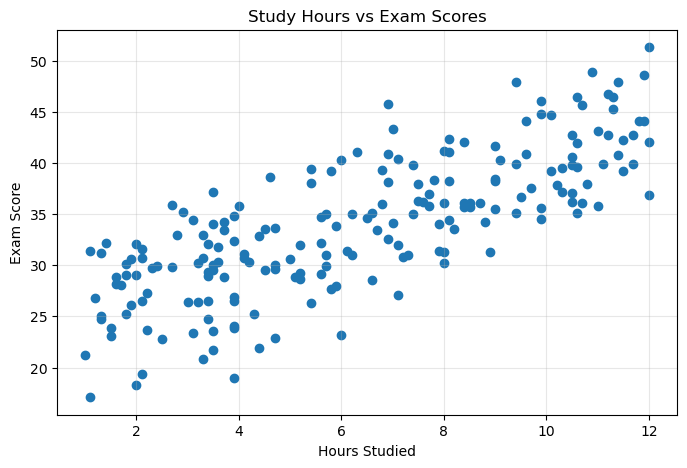

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(df["hours_studied"], df["exam_score"])

plt.title("Study Hours vs Exam Scores")
plt.xlabel("Hours Studied")
plt.ylabel("Exam Score")
plt.grid(True, alpha=0.3)

plt.show()

### 2.2 Scatter Plot Observations

- **Relationship:** The scatter plot shows a generally positive relationship between study hours and exam scores.
- **Direction:** The points follow an overall upward trend, indicating a positive slope.
- **Unusual observations:** No obvious unusual data points were visually identified.
- **Conclusion:** The observed pattern suggests that Simple Linear Regression may be a suitable model to investigate the relationship between study hours and exam scores. We will evaluate the model's performance later.

### 2.3 Understanding the Simple Linear Regression Equation

Simple Linear Regression represents the relationship between one input feature and a numerical target using a straight line.

The equation is:

\[
\hat{y} = b_0 + b_1x
\]

Where:

- \(x\): Number of hours studied.
- \(\hat{y}\): Predicted exam score.
- \(b_0\): Intercept, representing the predicted score when study hours are zero.
- \(b_1\): Slope, representing the change in predicted exam score for each additional study hour.

The slope and intercept are learned from the training data. Their actual values will be calculated when we fit the regression model.

## 3. Preparing Data for Simple Linear Regression

In this step, we select the input feature and target variable.

- `hours_studied` is the independent variable (X).
- `exam_score` is the dependent variable (y).
- We use one input feature because this is Simple Linear Regression.

Our objective is to train a model that predicts exam scores using study hours.

In [7]:
# Select the input feature (X) and target variable (y)

X = df[["hours_studied"]]
y = df["exam_score"]

# Display the first five observations
print("Input Feature (X):")
display(X.head())

print("Target Variable (y):")
display(y.head())

Input Feature (X):


,hours_studied
0,8.0
1,1.3
2,4.0
3,3.5
4,9.1


Target Variable (y):


0    30.2
1    25.0
2    35.8
3    34.0
4    40.3
Name: exam_score, dtype: float64

In [8]:
print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

Shape of X: (200, 1)
Shape of y: (200,)


In [9]:
print("Missing values in X:", X.isnull().sum().sum())
print("Missing values in y:", y.isnull().sum())

print("Data types:")
print(X.dtypes)
print("Target data type:", y.dtype)

Missing values in X: 0
Missing values in y: 0
Data types:
hours_studied    float64
dtype: object
Target data type: float64


### 4. Splitting Data into Training and Testing Sets

We split the dataset into training and testing sets.

- Training set: Used to learn the relationship between study hours and exam scores.
- Testing set: Used to evaluate predictions on observations not used during training.
- Test size: 20%
- Random state: 42, for reproducibility.

In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (160, 1)
X_test shape: (40, 1)
y_train shape: (160,)
y_test shape: (40,)


# Train a baseline model
Simple reference point for comparison

In [11]:
from sklearn.dummy import DummyRegressor

baseline_model = DummyRegressor(strategy="mean")
baseline_model.fit(X_train, y_train)

baseline_predictions = baseline_model.predict(X_test)

In [12]:
# What average did the baseline learn?
print("Training scores average:", y_train.mean())

# Display a few actual test scores and baseline predictions
comparison = pd.DataFrame({
    "Study Hours": X_test["hours_studied"].values,
    "Actual Score": y_test.values,
    "Baseline Prediction": baseline_predictions
})

display(comparison.head(10))

Training scores average: 33.85125000000001


,Study Hours,Actual Score,Baseline Prediction
0,5.2,28.7,33.85125
1,7.0,34.1,33.85125
2,9.9,34.5,33.85125
3,3.5,29.5,33.85125
4,10.7,36.1,33.85125
5,10.6,46.4,33.85125
6,3.9,23.9,33.85125
7,11.3,45.3,33.85125
8,9.9,44.8,33.85125
9,3.6,31.8,33.85125


## 6. Training the Simple Linear Regression Model

We train a Simple Linear Regression model to learn the relationship between study hours and exam scores.

Unlike the baseline model, Linear Regression uses the input feature `hours_studied` to estimate exam scores.

The model learns two parameters:
- Intercept (b0): The predicted score when study hours are zero.
- Slope (b1): The expected change in predicted score for each additional study hour.

The model is trained using only the training dataset.

In [13]:
from sklearn.linear_model import LinearRegression

# Create the Linear Regression model
model = LinearRegression()

# Learn from the training data
model.fit(X_train, y_train)

print("Linear Regression training completed!")

Linear Regression training completed!


In [14]:
b0 = model.intercept_
b1 = model.coef_[0]

print("Intercept (b0):", b0)
print("Slope (b1):", b1)

print(
    f"Regression equation: Predicted Score = {b0:.2f} + ({b1:.2f} × Study Hours)"
)

Intercept (b0): 23.784028523024055
Slope (b1): 1.6146305496352773
Regression equation: Predicted Score = 23.78 + (1.61 × Study Hours)


In [15]:
# Predict scores for the same test students
linear_predictions = model.predict(X_test)

comparison = pd.DataFrame({
    "Study Hours": X_test["hours_studied"].values,
    "Actual Score": y_test.values,
    "Baseline Prediction": baseline_predictions,
    "Linear Regression Prediction": linear_predictions
})

display(comparison.head(10).round(2))

,Study Hours,Actual Score,Baseline Prediction,Linear Regression Prediction
0,5.2,28.7,33.85,32.18
1,7.0,34.1,33.85,35.09
2,9.9,34.5,33.85,39.77
3,3.5,29.5,33.85,29.44
4,10.7,36.1,33.85,41.06
5,10.6,46.4,33.85,40.90
6,3.9,23.9,33.85,30.08
7,11.3,45.3,33.85,42.03
8,9.9,44.8,33.85,39.77
9,3.6,31.8,33.85,29.60


## 7. Evaluating the Models

We evaluate the baseline model and the Simple Linear Regression model using the same test dataset.

We use three metrics:

- **MAE (Mean Absolute Error):** the average absolute difference between actual and predicted scores. Lower is better.
- **RMSE (Root Mean Squared Error):** penalizes larger prediction errors more heavily. Lower is better.
- **R² Score (Coefficient of Determination):** measures how well the model explains variation in the target compared with predicting the test-set mean. A score closer to 1 generally indicates a better fit; a negative score means the model performs worse than that mean-based benchmark on the test data.

We use the test data only for evaluation, not for training the model.

In [17]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Baseline model metrics
baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_predictions))
baseline_r2 = r2_score(y_test, baseline_predictions)

# Linear Regression model metrics
linear_mae = mean_absolute_error(y_test, linear_predictions)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_predictions))
linear_r2 = r2_score(y_test, linear_predictions)

# Compare both models
metrics_comparison = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R² Score"],
    "Baseline Model": [baseline_mae, baseline_rmse, baseline_r2],
    "Linear Regression": [linear_mae, linear_rmse, linear_r2]
})

display(metrics_comparison.round(3))

,Metric,Baseline Model,Linear Regression
0,MAE,6.120,3.827
1,RMSE,7.303,4.378
2,R² Score,-0.005,0.639


## 8. Visualizing the Regression Line

A scatter plot displays the actual observations, while the regression line shows the scores predicted by our trained model.

This visualization helps us understand the direction of the relationship between study hours and exam scores, and how the model's predictions compare with the observed data.

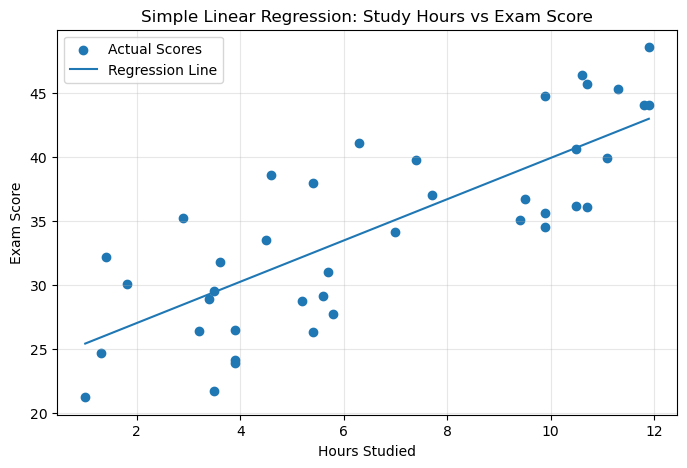

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

# Actual observations
plt.scatter(
    X_test["hours_studied"],
    y_test,
    label="Actual Scores"
)

# Predicted regression line
sorted_indices = X_test["hours_studied"].argsort()
X_sorted = X_test.iloc[sorted_indices]

plt.plot(
    X_sorted["hours_studied"],
    linear_predictions[sorted_indices],
    label="Regression Line"
)

plt.xlabel("Hours Studied")
plt.ylabel("Exam Score")
plt.title("Simple Linear Regression: Study Hours vs Exam Score")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

- Points above line             → positive residual.
- Points below line             → negative residual.
- Point near line               → small residual
- Points far away from the line → large residual.

## 9. Residual Analysis

A residual is the difference between an actual target value and its predicted value.

Residual analysis helps us identify patterns in prediction errors and assess whether a linear model is appropriate for the data.

A residual plot displays predicted values or input values on the x-axis and residuals on the y-axis. Ideally, residuals should be scattered around zero without a clear systematic pattern.

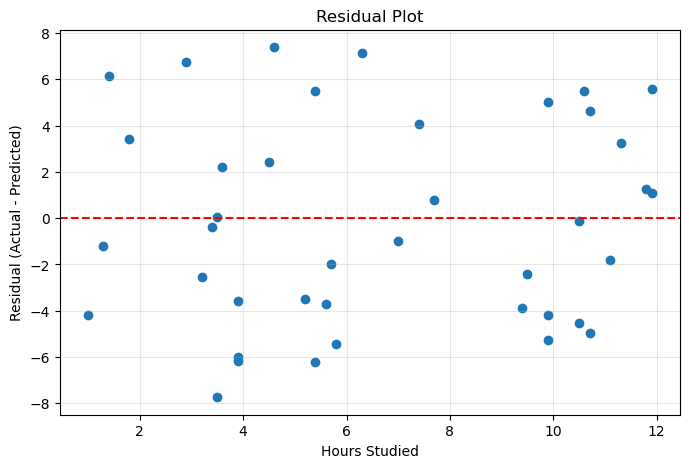

In [19]:
# Calculate residuals
residuals = y_test.to_numpy() - linear_predictions

# Plot residuals against study hours
plt.figure(figsize=(8, 5))

plt.scatter(X_test["hours_studied"], residuals)
plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Hours Studied")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residual Plot")
plt.grid(True, alpha=0.3)
plt.show()

In [20]:
residual_summary = pd.Series(residuals, name="Residuals")

print("Mean residual:", residual_summary.mean())
print("Minimum residual:", residual_summary.min())
print("Maximum residual:", residual_summary.max())
print("Mean absolute residual:", residual_summary.abs().mean())

Mean residual: -0.21187032370997202
Minimum residual: -7.735235446747527
Maximum residual: 7.388670948653672
Mean absolute residual: 3.8271943573079588


## 10. Making Predictions for New Data

After training and evaluating the model, we can use it to predict an exam score for a new study-hours value.

The new input is passed to the trained model using `predict()`. The output is an estimate, not a guaranteed exam result.

Predictions should be interpreted cautiously, especially for study-hour values outside the range represented in the training data.

In [21]:
new_student = pd.DataFrame({
    "hours_studied": [4, 8, 10]
})

predicted_scores = model.predict(new_student)

prediction_results = new_student.copy()
prediction_results["Predicted Exam Score"] = predicted_scores

display(prediction_results.round(2))

,hours_studied,Predicted Exam Score
0,4,30.24
1,8,36.70
2,10,39.93


## 11. Final Model Interpretation

The Simple Linear Regression model was trained to estimate exam scores using students' study hours.

The model learned the following regression equation:

`Predicted Exam Score = 23.78 + (1.61 × Study Hours)`

**Key findings:**

- The positive slope indicates that higher study hours are associated with higher predicted exam scores in this dataset.
- The model achieved an MAE of 3.827, meaning its predictions differed from actual scores by approximately 3.83 points on average in absolute terms on the test set.
- The RMSE was 4.378, and the R² score was 0.639 on the test set.
- The model performed better than the mean-based baseline on the selected test split.

**Limitations:**

- Study hours is the only input feature.
- Other factors affecting exam performance are not included.
- The model describes an association and does not establish that studying an additional hour causes a particular score increase.
- The results reflect this dataset and test split; performance may differ on new data.

In [22]:
final_results = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R² Score"],
    "Baseline Model": [
        baseline_mae,
        baseline_rmse,
        baseline_r2
    ],
    "Simple Linear Regression": [
        linear_mae,
        linear_rmse,
        linear_r2
    ]
})

display(final_results.round(3))

,Metric,Baseline Model,Simple Linear Regression
0,MAE,6.120,3.827
1,RMSE,7.303,4.378
2,R² Score,-0.005,0.639
